In [3]:
from pathlib import Path
import pandas as pd
import numpy as np

folder = Path(r"../30/sim/30_Re_100/Pos3_transformed_all")

files = sorted(folder.glob("*.csv"))

print(f"Found {len(files)} files")

layers = {}

Found 15 files


In [4]:
for file in files:

    layer = file.stem.split("_")[1]     # L03, L04 ...

    df = pd.read_csv(file)

    df["k"] = 0.5*(
        df["Re_tensor_0"] +
        df["Re_tensor_1"] +
        df["Re_tensor_2"]
    )

    layers[layer] = df

print(layers.keys())

dict_keys(['L03', 'L04', 'L05', 'L06', 'L07', 'L08', 'L09', 'L10', 'L11', 'L12', 'L13', 'L14', 'L15', 'L16', 'L17'])


In [5]:
stats = []

for layer, df in layers.items():

    k = df["k"]

    stats.append({

        "Layer": layer,

        "Mean k": k.mean(),

        "Median k": k.median(),

        "Max k": k.max(),

        "95 percentile": np.percentile(k,95),

        "Std": k.std()

    })

stats = pd.DataFrame(stats)

stats = stats.sort_values("Layer")

stats

,Layer,Mean k,Median k,Max k,95 percentile,Std
0,L03,0.061031,0.036596,0.375585,0.214510,0.068442
1,L04,0.063421,0.032956,0.375771,0.239879,0.073001
2,L05,0.061636,0.031003,0.374020,0.233690,0.072093
3,L06,0.061374,0.030712,0.337835,0.232038,0.071920
4,L07,0.065039,0.034310,0.332487,0.242909,0.075814
5,L08,0.062960,0.031328,0.358178,0.238777,0.073593
6,L09,0.062415,0.030533,0.343635,0.235322,0.073334
7,L10,0.064393,0.031168,0.343878,0.244336,0.075892
8,L11,0.062543,0.030926,0.356766,0.239369,0.073707
9,L12,0.061270,0.029910,0.338577,0.233195,0.072402


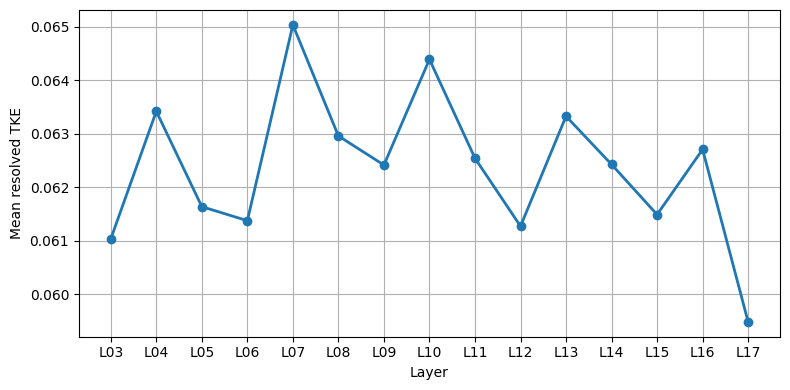

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))

plt.plot(
    stats["Layer"],
    stats["Mean k"],
    marker="o",
    linewidth=2
)

plt.ylabel("Mean resolved TKE")
plt.xlabel("Layer")
plt.grid(True)

plt.tight_layout()
plt.show()

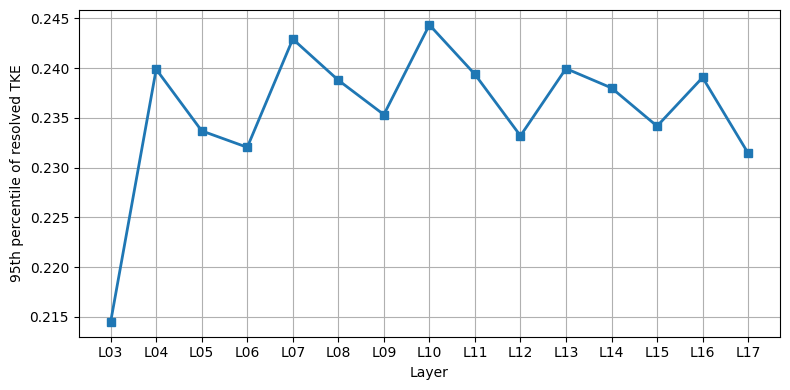

In [7]:
plt.figure(figsize=(8,4))

plt.plot(
    stats["Layer"],
    stats["95 percentile"],
    marker="s",
    linewidth=2
)

plt.ylabel("95th percentile of resolved TKE")
plt.xlabel("Layer")
plt.grid(True)

plt.tight_layout()
plt.show()

In [8]:
fractions = []

for layer, df in layers.items():

    k = df["k"]

    threshold = np.percentile(k,90)

    frac = (k>threshold).mean()

    fractions.append([layer,frac])

fractions = pd.DataFrame(fractions,
                         columns=["Layer","Fraction"])
fractions = fractions.sort_values("Layer")

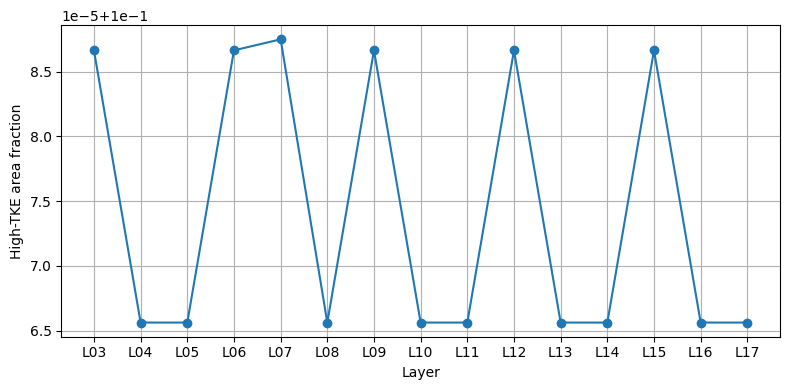

In [9]:
plt.figure(figsize=(8,4))

plt.plot(
    fractions["Layer"],
    fractions["Fraction"],
    marker="o"
)

plt.ylabel("High-TKE area fraction")
plt.xlabel("Layer")

plt.grid(True)

plt.tight_layout()
plt.show()

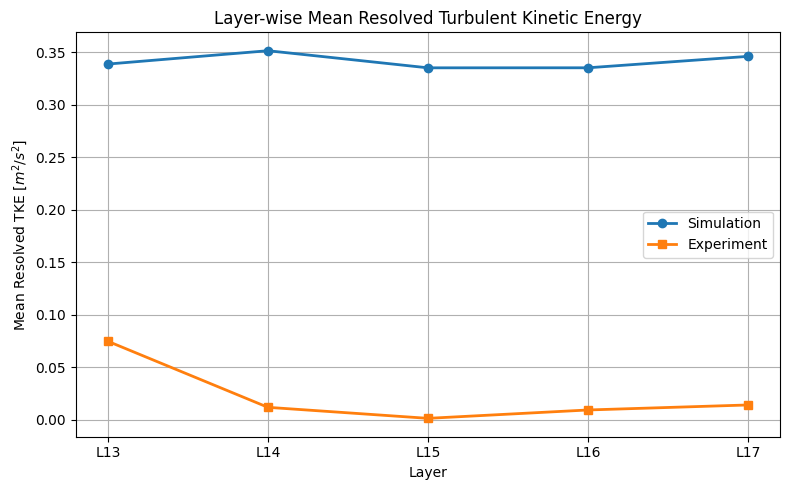

In [10]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# Paths
# -----------------------------
sim_folder = "../30/sim/30_Re_100/Pos3_transformed"
exp_folder = "../30/exp/30_Re_100/Pos3_transformed"

# -----------------------------
# Get file lists
# -----------------------------
sim_files = sorted(glob.glob(os.path.join(sim_folder, "*.csv")))
exp_files = sorted(glob.glob(os.path.join(exp_folder, "*.csv")))

layers = []
sim_mean = []
exp_mean = []

# -----------------------------
# Loop over layers
# -----------------------------
for sim_file in sim_files:

    # Extract layer name (L03, L04, ...)
    layer = os.path.basename(sim_file).split("_")[1]

    # Experimental filename
    exp_file = os.path.join(
        exp_folder,
        f"{layer}_Pos03_Re100_B0001_T_transformed.csv"
    )

    if not os.path.exists(exp_file):
        print(f"Missing experimental file for {layer}")
        continue

    # -----------------------------
    # Read files
    # -----------------------------
    sim = pd.read_csv(sim_file)
    exp = pd.read_csv(exp_file)

    # -----------------------------
    # Compute resolved TKE
    # -----------------------------
    sim["TKE"] = 0.5 * (
        sim["Re_tensor_0"] +
        sim["Re_tensor_1"] +
        sim["Re_tensor_2"]
    )

    # Experimental TKE already exists
    exp["TKE"] = exp["Turbulent_kinetic_energy"]

    # -----------------------------
    # Store statistics
    # -----------------------------
    layers.append(layer)

    sim_mean.append(sim["TKE"].max())
    exp_mean.append(exp["TKE"].max())

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(8,5))

plt.plot(
    layers,
    sim_mean,
    '-o',
    linewidth=2,
    label='Simulation'
)

plt.plot(
    layers,
    exp_mean,
    '-s',
    linewidth=2,
    label='Experiment'
)

plt.xlabel("Layer")
plt.ylabel("Mean Resolved TKE [$m^2/s^2$]")
plt.title("Layer-wise Mean Resolved Turbulent Kinetic Energy")

plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
exp = pd.read_csv(exp_file)

exp["k_check"] = 0.5*(
    exp["Stand_dev_Vx"]**2 +
    exp["Stand_dev_Vy"]**2 +
    exp["Stand_dev_Vz"]**2
)

print(exp[["Turbulent_kinetic_energy","k_check"]].head(10))

print(exp["Turbulent_kinetic_energy"].mean())
print(exp["k_check"].mean())

   Turbulent_kinetic_energy   k_check
0                  0.001973  0.001973
1                  0.001633  0.001633
2                  0.001284  0.001284
3                  0.001278  0.001278
4                  0.001259  0.001259
5                  0.001262  0.001262
6                  0.001329  0.001329
7                  0.001356  0.001356
8                  0.001327  0.001327
9                  0.001159  0.001159
0.00010657750582750584
0.00010657445710416667


In [12]:
print(sim[["Re_tensor_0","Re_tensor_1","Re_tensor_2"]].describe())

        Re_tensor_0   Re_tensor_1   Re_tensor_2
count  9.144000e+03  9.144000e+03  9.144000e+03
mean   1.127830e-02  1.085850e-02  9.682278e-02
std    1.589550e-02  1.720892e-02  1.458890e-01
min    1.950940e-08  8.676303e-09  1.496295e-10
25%    4.319951e-04  3.998626e-04  1.142889e-04
50%    2.605280e-03  3.455432e-03  4.913100e-03
75%    2.046517e-02  1.417163e-02  1.707741e-01
max    1.019564e-01  1.900907e-01  5.673862e-01


In [13]:
print(sim["av_u_Magnitude"].describe())

count    9144.000000
mean        0.277262
std         0.204365
min         0.000369
25%         0.111408
50%         0.227893
75%         0.426754
max         0.831570
Name: av_u_Magnitude, dtype: float64


In [14]:
sim["TKE"] = 0.5*(
    sim["Re_tensor_0"] +
    sim["Re_tensor_1"] +
    sim["Re_tensor_2"]
)

In [15]:
print(sim["TKE"].describe())
print(sim["TKE"].mean())

count    9.144000e+03
mean     5.947979e-02
std      7.233631e-02
min      9.357204e-08
25%      6.241032e-03
50%      2.605864e-02
75%      9.131328e-02
max      3.462894e-01
Name: TKE, dtype: float64
0.059479788184668606
